# Designing a Topic Forest for Findable and Stable Learning History
**HCI 2026 – Group 19 – Milestone 3 (simplified model, working version)**

In our prototype the student asks the AI one prompt after another, and after **every** prompt the knowledge tree is updated. At each step the system decides where the new prompt goes:

- **(a)** add it to an existing topic,
- **(b)** open a new subtopic under an existing topic (new branch),
- **(c)** open a new topic directly under the subject (new tree),
- **(e)** open a new topic *and* move related older prompts into it (reorganize).

This decision trades off **semantic fit**, a **tidy structure** (topics neither overloaded nor near-empty) and **stability** (moving old prompts breaks the user's mental map). We formulate **one step** as an integer program, solve it with Gurobi, apply the result to the tree and continue with the next prompt. Running this over a scripted study session gives the sequence of trees the user would see.

**How to use this notebook.** All numbers that we may want to change live in three cells: the session script (Section 1), the judge scores (Section 2) and the weights (Section 3). Edit them and re-run all cells.

*Scope of this version:* one subject ("deep learning"), candidate new topics come with a parent fixed by the judge, at most one new topic per step, old topics are never deleted.

**Setup.** In Google Colab the next cell downloads the repository (the notebook needs `session.py`, `visualization.py`, `judge.py` and `judge_scores.json` from it) and installs Gurobi; Gurobi's free size-limited license that comes with `pip install gurobipy` is enough for this model (about 60 variables per step). Run locally, the cell does nothing.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/UxAzhangxiaohua/hci_m3/blob/main/ui_optimization.ipynb)

In [1]:
import os, sys, subprocess

REPO = "https://github.com/UxAzhangxiaohua/hci_m3.git"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.exists("hci_m3"):
        subprocess.run(["git", "clone", "-q", REPO], check=True)
    os.chdir("hci_m3")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gurobipy"], check=True)
print("running in", "Colab" if IN_COLAB else "a local Jupyter", "| working directory:", os.getcwd())

running in a local Jupyter | working directory: /home/claude/out


In [2]:
# !pip install -r requirements.txt   # gurobipy, numpy, matplotlib, pandas, pillow
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from gurobipy import Model, GRB, quicksum

pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 60)

# 1. The scripted study session
***
**Start.** The student has already asked two prompts, so the tree starts like the one in our prototype:

```
deep learning                      (the subject = root of the tree)
├── Deep learning basics   ● p0    "Explain what deep learning is"
└── Gradient descent       ● p1    "What is gradient descent?"
```

**Then eight new prompts arrive one by one** (`n1` … `n8`). For some prompts the analysis step (an LLM, `newNode` in our `turnAnalysis.ts`) also **proposes a candidate new topic** together with the parent it would hang under. A candidate does **not** exist yet: the solver decides whether to create it.

| id | Topic | Parent | Where it comes from |
|---|---|---|---|
| `DLB` | Deep learning basics | deep learning | exists at the start |
| `GD` | Gradient descent | deep learning | exists at the start |
| `LR` | Learning rate | Gradient descent | proposed at step 1 → would be a **new branch** |
| `BP` | Backpropagation | deep learning | proposed at step 2 → would be a **new tree** |
| `SGDV` | SGD variants | Gradient descent | proposed at step 4 → would be a **new branch** |
| `OPT` | Optimizers | Gradient descent | proposed at step 5 → would be a **new branch** |
| `VG` | Vanishing gradients | Backpropagation | proposed at steps 6 and 7 → would be a **new branch** |


`w` is the cost weight of moving a prompt later on. **We set `w = 1` for every prompt** (all moves cost the same). This is an assumption: in the app it could be derived from how often a prompt was reopened recently.

The session is defined in **`session.py`** (next to this notebook). Both this notebook and the judge script `judge.py` read it, so the judge scores exactly the prompts and topics that are optimized here. To change the session, edit `session.py`, re-run `judge.py`, then re-run this notebook.

*The prompts and proposals are a scripted example. Replace them with the real session used in Milestone 4.*

In [3]:
from session import SUBJECT, INITIAL_TOPICS, INITIAL_PROMPTS, SESSION, AUTHOR_SCORES, all_topics, all_prompts

ALL_LABELS = {c: t["label"] for c, t in all_topics().items()}

pd.DataFrame({
    "prompt": [s["text"] for s in SESSION],
    "candidate proposed by the analysis step": [
        ", ".join(f'{t["label"]} (under {ALL_LABELS.get(t["parent"], t["parent"])})' for t in s["candidates"].values()) or "-"
        for s in SESSION],
}, index=pd.Index([f'{k + 1}: {s["id"]}' for k, s in enumerate(SESSION)], name="step"))

,prompt,candidate proposed by the analysis step
step,,
1: n1,What does the learning rate do?,Learning rate (under Gradient descent)
2: n2,How does backpropagation compute the gradients?,Backpropagation (under deep learning)
3: n3,Chain rule through a 2-layer network,-
4: n4,SGD vs. mini-batch gradient descent,SGD variants (under Gradient descent)
5: n5,How does Adam adapt the learning rate?,Optimizers (under Gradient descent)
6: n6,Why do gradients vanish in deep networks?,Vanishing gradients (under Backpropagation)
7: n7,Does the gradient shrink layer by layer with sigmoid?,Vanishing gradients (under Backpropagation)
8: n8,What is momentum in SGD?,-


# 2. Semantic fit $s_{pc}$ from the LLM judge
***
The solver cannot judge meaning, so the fit of prompt $p$ to topic $c$ comes from outside the solver. **An LLM judge** (`judge.py`) rates every prompt of the session against every topic that exists or is proposed during the session with this rubric:

| score | meaning |
|---|---|
| 5 | the question is squarely about this topic |
| 4 | it belongs to a more specific subtopic of this topic that is not in the list |
| 3 | same broader area, different topic |
| 2 | loosely related |
| 1 | unrelated |

**Procedure.** One call per prompt lists all topics with their path in the tree, in a **new random order and under opaque ids** (`t1`, `t2`, …) in every call, so neither the order nor our abbreviations can influence the score. Temperature 0, JSON answer, **3 independent runs per prompt, median as the final score**. The model, date, settings, the full prompt text (see the appendix) and every raw answer are stored in `judge_scores.json`.

We rescale the score to $s_{pc} = (j_{pc}-1)/4 \in \{0, 0.25, 0.5, 0.75, 1\}$. In the full system it could be mixed with an embedding similarity, $s = \omega\,\tfrac{j-1}{4} + (1-\omega)\tfrac{1+\cos}{2}$; here we use the judge only ($\omega = 1$).

The scores of **old prompts for new candidates** matter too: they decide whether moving an old prompt into a new topic improves the fit.

**To create the scores** (once, in a terminal in this folder):
```
export ANTHROPIC_API_KEY=...        # or: --provider openai with OPENAI_API_KEY
python judge.py                     # -> judge_scores.json
```
If `judge_scores.json` does not exist yet, the notebook falls back to scores assigned by the authors (`AUTHOR_SCORES` in `session.py`) and says so below.

In [4]:
import os, json

SCORE_FILE = "judge_scores.json"
if os.path.exists(SCORE_FILE):
    with open(SCORE_FILE) as f:
        JUDGE_RESULT = json.load(f)
    JUDGE = JUDGE_RESULT["scores"]
    meta = JUDGE_RESULT["meta"]
    SCORE_SOURCE = f'LLM judge: {meta["model"]} ({meta["provider"]}), {meta["date_utc"][:10]}'
    stale = [p for p in all_prompts() if p not in JUDGE or set(JUDGE[p]) != set(ALL_LABELS)
             or JUDGE_RESULT["prompts"].get(p) != all_prompts()[p]]
    assert not stale, f"session.py changed since the judge ran (prompts {stale}); re-run judge.py"
    display(pd.Series({k: meta[k] for k in ["provider", "model", "date_utc", "temperature", "runs_per_prompt",
                                            "aggregation", "topic_order", "prompt_version", "prompt_sha256"]},
                      name="judge run").to_frame())
else:
    JUDGE_RESULT = None
    JUDGE = AUTHOR_SCORES
    SCORE_SOURCE = "author-assigned scores (judge_scores.json not found: run judge.py)"
print("Scores used:", SCORE_SOURCE)

def s(p, c):
    return (JUDGE[p].get(c, 1) - 1) / 4

# full table, one row per prompt, one column per topic (existing or candidate)
S_TABLE = pd.DataFrame([[s(p, c) for c in ALL_LABELS] for p in all_prompts()],
                       index=list(all_prompts()), columns=list(ALL_LABELS.values()))
S_TABLE

Scores used: author-assigned scores (judge_scores.json not found: run judge.py)


,Deep learning basics,Gradient descent,Learning rate,Backpropagation,SGD variants,Optimizers,Vanishing gradients
p0,1.00,0.25,0.00,0.25,0.00,0.00,0.25
p1,0.25,1.00,0.25,0.25,0.50,0.50,0.00
n1,0.00,0.75,1.00,0.00,0.00,0.50,0.00
n2,0.25,0.50,0.00,1.00,0.00,0.00,0.50
n3,0.00,0.25,0.00,1.00,0.00,0.00,0.25
n4,0.00,0.75,0.00,0.00,1.00,0.75,0.00
n5,0.00,0.50,0.50,0.00,0.25,1.00,0.00
n6,0.25,0.25,0.00,0.75,0.00,0.00,1.00
n7,0.25,0.00,0.00,0.75,0.00,0.00,1.00
n8,0.00,0.75,0.00,0.00,0.50,1.00,0.00


## Is the judge reliable?
***
Two checks, both reported in the critical examination:

1. **Consistency across runs**: how often the three runs gave exactly the same score (from `judge_scores.json`).
2. **Agreement with humans**: two group members rate every prompt–topic pair with the same rubric, independently and **without looking at the judge's scores**. Create the blank sheet with `python judge.py --rating-sheet human_ratings.csv`, fill the columns `rater_A` and `rater_B` (1–5), save it in this folder and re-run this cell.

We report exact agreement, agreement within one point, the quadratic-weighted Cohen's $\kappa$ (standard for ordinal scales; 1 = perfect, 0 = chance) and the Spearman rank correlation, for judge vs. each rater and rater A vs. rater B as the human baseline.

In [5]:
def weighted_kappa(a, b, k=5):
    # quadratic-weighted Cohen's kappa for ratings 1..k
    a, b = np.asarray(a, int) - 1, np.asarray(b, int) - 1
    O = np.zeros((k, k))
    for i, j in zip(a, b):
        O[i, j] += 1
    E = np.outer(O.sum(1), O.sum(0)) / O.sum()
    W = np.array([[(i - j) ** 2 for j in range(k)] for i in range(k)]) / (k - 1) ** 2
    return 1 - (W * O).sum() / (W * E).sum()

def agreement(a, b):
    a, b = pd.Series(a, dtype=float), pd.Series(b, dtype=float)
    return {"pairs": len(a), "exact": (a == b).mean(), "within 1": ((a - b).abs() <= 1).mean(),
            "weighted kappa": weighted_kappa(a, b), "Spearman": a.rank().corr(b.rank())}

if JUDGE_RESULT:
    ra = JUDGE_RESULT["run_agreement"]
    print(f'1. Runs: identical in all {JUDGE_RESULT["meta"]["runs_per_prompt"]} runs for '
          f'{ra["identical_in_all_runs"]}/{ra["pairs"]} pairs, differ by at most 1 point for '
          f'{ra["max_minus_min_at_most_1"]}/{ra["pairs"]}.')
else:
    print("1. Runs: no judge run yet.")

RATING_FILE = "human_ratings.csv"
if os.path.exists(RATING_FILE):
    H = pd.read_csv(RATING_FILE).dropna(subset=["rater_A", "rater_B"])
    H["judge"] = [JUDGE[p].get(c, 1) for p, c in zip(H.prompt_id, H.topic_id)]
    print(f"2. Humans ({len(H)} rated pairs, scores used: {SCORE_SOURCE}):")
    display(pd.DataFrame({"judge vs. rater A": agreement(H.judge, H.rater_A),
                          "judge vs. rater B": agreement(H.judge, H.rater_B),
                          "rater A vs. rater B": agreement(H.rater_A, H.rater_B)}).T)
    H["gap"] = (H.judge - (H.rater_A + H.rater_B) / 2).abs()
    print("Largest disagreements between the judge and the raters:")
    display(H.sort_values("gap", ascending=False)[["prompt", "topic_path", "judge", "rater_A", "rater_B"]].head(5))
else:
    print("2. Humans: no human_ratings.csv yet (create it with: python judge.py --rating-sheet human_ratings.csv).")

1. Runs: no judge run yet.
2. Humans: no human_ratings.csv yet (create it with: python judge.py --rating-sheet human_ratings.csv).


# 3. Design parameters and weights
***
All weights are on the scale of $s_{pc}\in[0,1]$, i.e. "how much fit is this worth"; one judge level is worth 0.25.

| Symbol | Value | Meaning and justification |
|---|---|---|
| $U$ | 3 | Preferred maximum prompts per topic. Small on purpose so that overload happens within a short session; for real use ≈ 5–7 (our app splits branches above 7 leaves). |
| $L$ | 2 | Preferred minimum prompts per **new** topic. A topic with one prompt adds a row but no grouping. |
| $\lambda$ | 0.20 | Cost of opening a new topic: it must improve fit by more than about one judge level, together with $\beta$ for a one-prompt topic. |
| $\beta$ | 0.15 | Cost per prompt above $U$ or below $L$. Below one judge level, so balance never outweighs a clear semantic difference. |
| $\mu$ | 0.10 | Cost per moved old prompt (times its weight $w_p$). |
| $F$ | 0.15 | Fixed cost if *anything* old moves: the first change to a familiar structure is the most noticeable one. |
| `MAX_NEW` | 1 | At most one new topic per step, so the tree grows slowly. |

In [6]:
PARAMS = dict(
    U=3,          # preferred max prompts per topic
    L=2,          # preferred min prompts per new topic
    lam=0.20,     # cost of opening a new topic
    beta=0.15,    # cost per prompt of overflow / underflow
    mu=0.10,      # cost per moved prompt (times w_p)
    F=0.15,       # fixed cost of any reorganization
    MAX_NEW=1,    # max number of new topics per step
)

# 4. The integer program for one step
***
At a step, the tree before the step is fixed input:

- $C^{old}$: topics that exist, $C^{new}$: candidates proposed for this prompt, $C = C^{old}\cup C^{new}$
- $P^{old}$: prompts already in the tree, each in topic $c^0(p)$; $n$: the new prompt; $P = P^{old}\cup\{n\}$

### Decision variables
| Variable | Meaning |
|---|---|
| $q_{pc}\in\{0,1\}$ | prompt $p$ is placed in topic $c$ after this step |
| $y_c\in\{0,1\}$, $c\in C^{new}$ | candidate $c$ is created |
| $m_p\in\{0,1\}$, $p\in P^{old}$ | old prompt $p$ is moved away from $c^0(p)$ |
| $z\in\{0,1\}$ | a reorganization happens in this step |
| $o_c, u_c\ge 0$ | slack: topic $c$ over $U$ / new topic under $L$ |

### Constraints
$$
\begin{aligned}
&\textstyle\sum_{c\in C} q_{pc} = 1 && \forall p\in P && \text{(1) each prompt in exactly one topic}\\
&q_{pc} \le y_c && \forall p\in P,\ c\in C^{new} && \text{(2) only into topics that exist}\\
&\textstyle y_c \le \sum_{p} q_{pc} && \forall c\in C^{new} && \text{(3) no empty new topic}\\
&\textstyle \sum_{p} q_{pc} \le U + o_c && \forall c\in C && \text{(4) too full (soft)}\\
&\textstyle \sum_{p} q_{pc} \ge L\,y_c - u_c && \forall c\in C^{new} && \text{(5) too sparse (soft)}\\
&m_p = 1 - q_{p,c^0(p)} && \forall p\in P^{old} && \text{(6) track moves}\\
&m_p \le z && \forall p\in P^{old} && \text{(7) any move is a reorganization}\\
&\textstyle\sum_{c\in C^{new}} y_c \le \texttt{MAX\_NEW} && && \text{(8) slow growth}
\end{aligned}
$$

### Objective
$$
\max\;
\underbrace{\sum_{p,c} s_{pc}\,q_{pc}}_{\text{semantic fit}}
-\underbrace{\lambda\sum_{c\in C^{new}} y_c}_{\text{new topics}}
-\underbrace{\beta\Big(\sum_{c\in C} o_c+\sum_{c\in C^{new}}u_c\Big)}_{\text{imbalance}}
-\underbrace{\mu\sum_{p\in P^{old}} w_p\,m_p - F\,z}_{\text{disruption}}
$$

Without (4), (5) and the disruption terms, the optimum would be "put every prompt in its best topic", which a simple rule can find. These terms create the trade-off.

**State.** A *state* is the tree at a moment: which topics exist (`topics`), where every prompt is (`assign`) and the move weights (`w`). `solve_step` takes the state and the next prompt and returns where every prompt goes after the step.

In [7]:
def initial_state():
    return dict(topics={c: dict(t) for c, t in INITIAL_TOPICS.items()},
                assign={p: d["topic"] for p, d in INITIAL_PROMPTS.items()},
                w={p: d["w"] for p, d in INITIAL_PROMPTS.items()})

def candidates_of(state, step):
    # candidates proposed for this step that do not exist yet
    return {c: t for c, t in step["candidates"].items() if c not in state["topics"]}

def solve_step(state, step, params=PARAMS, verbose=False):
    U, L = params["U"], params["L"]
    n = step["id"]
    C_old = list(state["topics"])
    C_new = list(candidates_of(state, step))
    C = C_old + C_new
    P_old = list(state["assign"])
    P = P_old + [n]
    c0 = state["assign"]

    # ==== 1. Create the (empty) model ====
    model = Model(f"step_{n}")
    model.Params.OutputFlag = 1 if verbose else 0

    # ==== 2. Add decision variables ====
    q = {(p, c): model.addVar(vtype=GRB.BINARY, name=f"q[{p},{c}]") for p in P for c in C}
    y = {c: model.addVar(vtype=GRB.BINARY, name=f"y[{c}]") for c in C_new}
    m = {p: model.addVar(vtype=GRB.BINARY, name=f"m[{p}]") for p in P_old}
    z = model.addVar(vtype=GRB.BINARY, name="z")
    o = {c: model.addVar(lb=0, name=f"o[{c}]") for c in C}
    u = {c: model.addVar(lb=0, name=f"u[{c}]") for c in C_new}

    # ==== 3. Add constraints ====
    for p in P:                                                                   # (1)
        model.addConstr(quicksum(q[p, c] for c in C) == 1, name=f"one_topic[{p}]")
    for c in C_new:
        for p in P:                                                               # (2)
            model.addConstr(q[p, c] <= y[c], name=f"exists[{p},{c}]")
        model.addConstr(y[c] <= quicksum(q[p, c] for p in P), name=f"not_empty[{c}]")        # (3)
        model.addConstr(quicksum(q[p, c] for p in P) >= L * y[c] - u[c], name=f"sparse[{c}]") # (5)
    for c in C:                                                                   # (4)
        model.addConstr(quicksum(q[p, c] for p in P) <= U + o[c], name=f"full[{c}]")
    for p in P_old:
        model.addConstr(m[p] == 1 - q[p, c0[p]], name=f"moved[{p}]")              # (6)
        model.addConstr(m[p] <= z, name=f"reorg[{p}]")                            # (7)
    model.addConstr(quicksum(y.values()) <= params["MAX_NEW"], name="max_new")   # (8)

    # ==== 4. Specify objective function ====
    fit = quicksum(s(p, c) * q[p, c] for p in P for c in C)
    growth = params["lam"] * quicksum(y.values())
    imbalance = params["beta"] * (quicksum(o.values()) + quicksum(u.values()))
    disruption = params["mu"] * quicksum(state["w"][p] * m[p] for p in P_old) + params["F"] * z
    model.setObjective(fit - growth - imbalance - disruption, GRB.MAXIMIZE)

    # ==== 5. Optimize model ====
    model.optimize()
    assert model.Status == GRB.OPTIMAL, f"Gurobi status {model.Status}"

    # ==== 6. Extract solution: where every prompt is after this step ====
    new_assign = {p: next(c for c in C if q[p, c].X > 0.5) for p in P}
    return new_assign, model.ObjVal

`evaluate_step` scores **any** decision for a step with the same objective, so that we can compare the optimum with human-made rules. On the solver's decision it must return the solver's objective value (a check of the implementation). `action` translates a decision into (a)/(b)/(c)/(e).

In [8]:
def evaluate_step(state, step, new_assign, params=PARAMS):
    U, L = params["U"], params["L"]
    n, cands = step["id"], candidates_of(state, step)
    P = list(state["assign"]) + [n]
    topics = list(state["topics"]) + list(cands)
    size = {c: sum(new_assign[p] == c for p in P) for c in topics}
    created = [c for c in cands if size[c] > 0]
    moved = [p for p in state["assign"] if new_assign[p] != state["assign"][p]]
    over = sum(max(0, size[c] - U) for c in topics)
    under = sum(max(0, L - size[c]) for c in created)
    parts = {
        "fit": sum(s(p, new_assign[p]) for p in P),
        "new topics": -params["lam"] * len(created),
        "imbalance": -params["beta"] * (over + under),
        "disruption": -(params["mu"] * sum(state["w"][p] for p in moved) + params["F"] * (len(moved) > 0)),
    }
    parts["objective"] = sum(parts.values())
    return parts

def action(state, step, new_assign):
    c = new_assign[step["id"]]
    moved = [p for p in state["assign"] if new_assign[p] != state["assign"][p]]
    if c in state["topics"]:
        base = "(a) add to existing topic"
    elif step["candidates"][c]["parent"] == SUBJECT:
        base = "(c) new tree"
    else:
        base = "(b) new branch"
    return f"(e) reorganize: move {', '.join(moved)} + {base[4:]}" if moved else base

def code_of(act):        # short letter for tables: a, b, c, or e
    return act[1]

# 5. Run the session step by step
***
`run_session` starts from the initial tree, and for each new prompt: asks the decision rule (here the IP) where everything goes, records the action, applies it to the tree (creates the chosen topic, moves prompts) and continues with the next prompt.

In [9]:
def apply(state, step, new_assign):
    topics = dict(state["topics"])
    for c, t in candidates_of(state, step).items():
        if c in new_assign.values():
            topics[c] = dict(t)
    return dict(topics=topics, assign=dict(new_assign), w={**state["w"], step["id"]: step["w"]})

def ip_policy(state, step, params):
    return solve_step(state, step, params)[0]

def run_session(policy=ip_policy, params=PARAMS):
    state, history = initial_state(), []
    for k, step in enumerate(SESSION, start=1):
        new_assign = policy(state, step, params)
        history.append(dict(k=k, step=step, before=state, after=apply(state, step, new_assign),
                            action=action(state, step, new_assign),
                            parts=evaluate_step(state, step, new_assign, params), params=params))
        state = history[-1]["after"]
    return history

ip_history = run_session()

# check: in every step our evaluation equals Gurobi's objective value
for h in ip_history:
    obj = solve_step(h["before"], h["step"])[1]
    assert abs(obj - h["parts"]["objective"]) < 1e-6, (h["k"], obj, h["parts"])
print("check passed: Gurobi objective == evaluate_step in all", len(ip_history), "steps\n")

def topic_label(state, c):
    return state["topics"][c]["label"]

pd.DataFrame({
    "new prompt": [h["step"]["text"] for h in ip_history],
    "placed in": [topic_label(h["after"], h["after"]["assign"][h["step"]["id"]]) for h in ip_history],
    "action": [h["action"] for h in ip_history],
    "objective": [h["parts"]["objective"] for h in ip_history],
}, index=pd.Index([h["k"] for h in ip_history], name="step"))

Restricted license - for non-production use only - expires 2028-11-29


check passed: Gurobi objective == evaluate_step in all 8 steps



,new prompt,placed in,action,objective
step,,,,
1,What does the learning rate do?,Gradient descent,(a) add to existing topic,2.75
2,How does backpropagation compute the gradients?,Backpropagation,(c) new tree,3.40
3,Chain rule through a 2-layer network,Backpropagation,(a) add to existing topic,4.75
4,SGD vs. mini-batch gradient descent,Gradient descent,(a) add to existing topic,5.50
5,How does Adam adapt the learning rate?,Optimizers,(b) new branch,6.15
6,Why do gradients vanish in deep networks?,Backpropagation,(a) add to existing topic,7.25
7,Does the gradient shrink layer by layer with sigmoid?,Vanishing gradients,(e) reorganize: move n6 + new branch,8.05
8,What is momentum in SGD?,Optimizers,(a) add to existing topic,9.50


To see what Gurobi does inside one step, here is the full solver log for **step 7**, the reorganization:

In [10]:
h7 = ip_history[6]
_ = solve_step(h7["before"], h7["step"], verbose=True)

Set parameter OutputFlag to value 1


Gurobi Optimizer version 14.0.0 build v14.0.0rc1 (linux64 - "Ubuntu 24.04.5 LTS")


CPU model: Intel(R) Xeon(R) Processor @ 2.10GHz, instruction set [SSE2|AVX|AVX2|AVX512]


Thread count: 2 physical cores, 2 logical processors, using up to 2 threads


Optimize a model with 42 rows, 61 columns and 167 nonzeros (Max)


Model fingerprint: 0xd6f77c7a


... (17 outputs left out)

Thread count was 2 (of 2 available processors)


Solution count 2: 8.05 4.3 


Optimal solution found (tolerance 1.00e-04)


Best objective 8.050000000000e+00, best bound 8.050000000000e+00, gap 0.0000%


# 6. Showing the session as a growing knowledge tree
***
Each tree is drawn the way the prototype's **tree view** shows it: the subject sits at the root at the bottom, topics branch upwards, and the dots on a topic are its prompts.

- **blue dot** = the prompt that arrived in this step, **orange dot** = an old prompt moved in this step (the dashed arrow shows from where), gray dot = unchanged;
- **dashed orange box** = topic created in this step;
- the small line under a topic gives its number of prompts and turns red if it is over $U$ or (new topic) under $L$, i.e. where the imbalance penalty applies.

The drawing functions are in **`visualization.py`** next to this notebook, so here we only call them:

| function | shows |
|---|---|
| `show_session(history)` | one tree per step (grid) |
| `show_step(history, k)` | step `k`, before and after |
| `animate_step(history, k)` | step `k` as an animation |
| `animate_session(history)` | the whole session as an animation |
| `show_final_trees({name: history, ...})` | final trees of several designs side by side |
| `draw_tree(state, ax)` | one tree on a matplotlib axis, for custom figures |

`history` is what `run_session` returns. `%autoreload` makes edits in `visualization.py` take effect without restarting the kernel.

In [11]:
# all drawing and animation code lives in visualization.py (same folder as this notebook)
%load_ext autoreload
%autoreload 2
from visualization import draw_tree, show_session, show_step, show_final_trees, animate_step, animate_session

## Visualization: the whole session with the IP
Read the panels left to right, top to bottom. Each panel is the tree the user sees **after** that step.

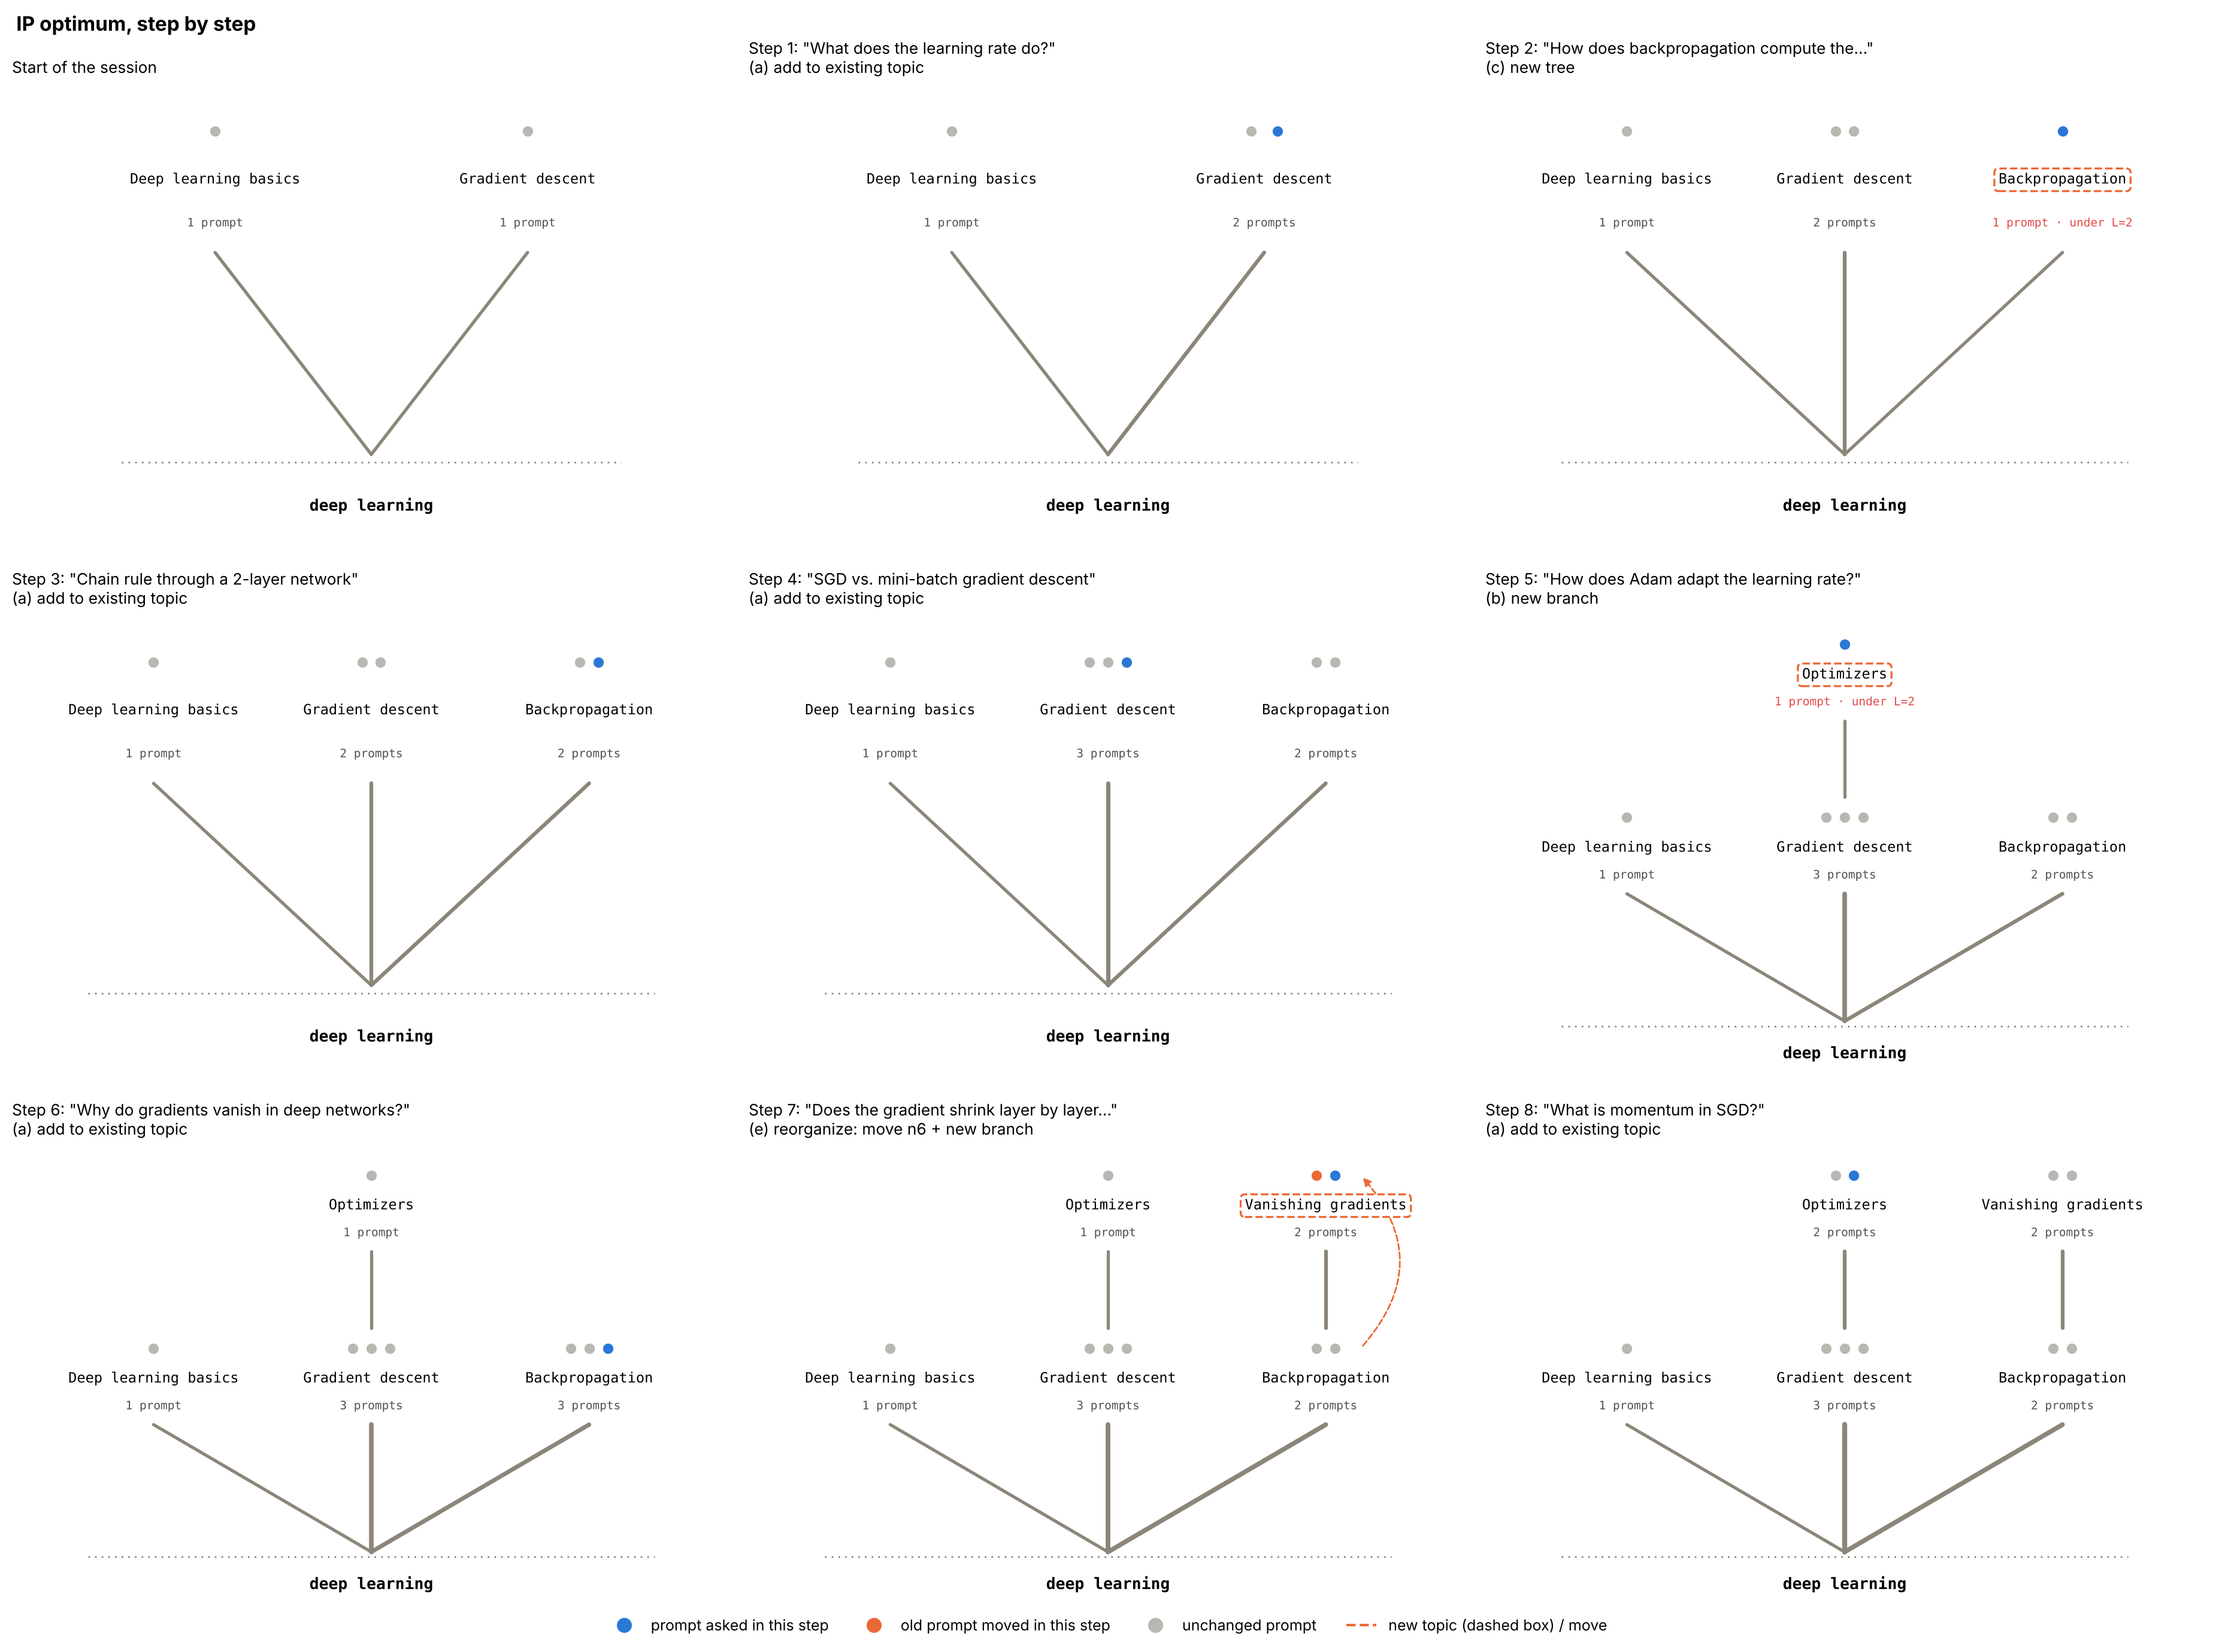

In [12]:
show_session(ip_history, "IP optimum, step by step")

## Visualization: one step in detail
Change `k` to look at any step.

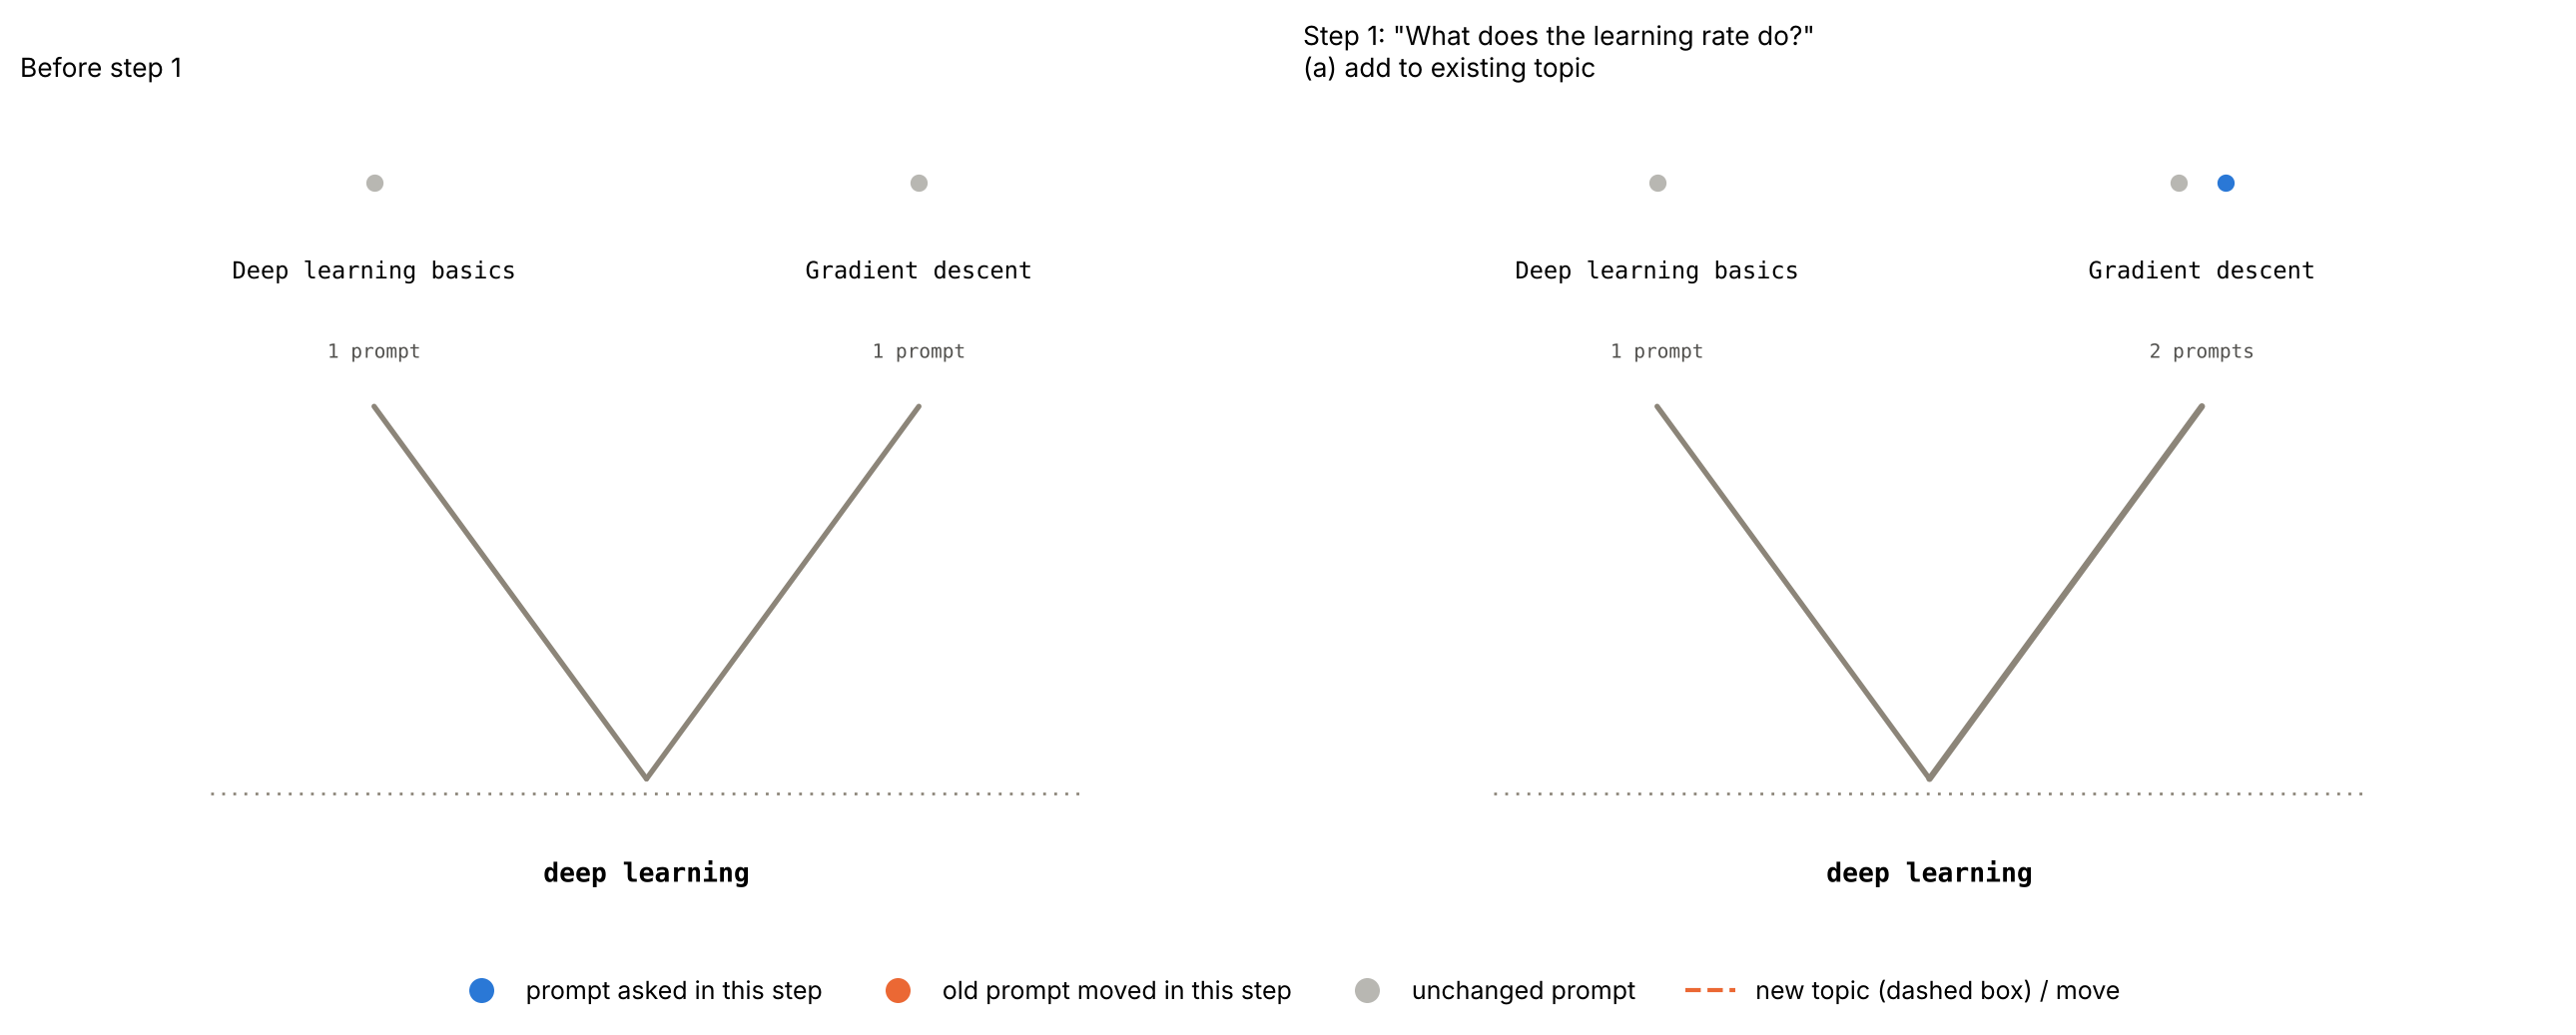

In [13]:
show_step(ip_history, k=1)

## Animation: watch a step happen
The same step as an animation: the tree before the step morphs into the tree after it. The new prompt drops in (blue), moved prompts glide to their new topic (orange), a newly created topic fades in. Use the player controls below the figure (play, pause, step frame by frame, loop).

`animate_step(history, k)` animates one step; `animate_session(history)` plays the whole session. With `gif="file.gif"` the animation is also saved as a GIF for slides or the report.

In [14]:
animate_step(ip_history, k=7)

In [ ]:
# the whole session (8 steps); add gif="session_ip.gif" to save it for slides
animate_session(ip_history)

## Why each decision? (computed from the current scores and weights)
For every step we compare the IP's decision with the two simple options: the **best existing topic** for the new prompt, and the **best new topic without moving anything**. *Margin* is how much better the IP's choice is than the best of the other options; a small margin means a small change of a weight would flip the decision (see the what-if analysis). This table is recomputed from the current scores, so it stays correct after running the judge or changing a weight.

In [16]:
def explain_session(history):
    rows = []
    for h in history:
        state, step, n = h["before"], h["step"], h["step"]["id"]
        keep = lambda c: {**state["assign"], n: c}                  # place n in c, nothing else moves
        opt = lambda c: evaluate_step(state, step, keep(c))["objective"]
        best_old = max(state["topics"], key=opt)
        cands = list(candidates_of(state, step))
        best_new = max(cands, key=opt) if cands else None
        ip = h["parts"]["objective"]
        others = [opt(best_old)] + ([opt(best_new)] if best_new else [])
        others = [v for v, c in zip(others, [best_old, best_new]) if keep(c) != h["after"]["assign"]]
        rows.append({
            "IP decision": h["action"],
            "IP": ip,
            "best existing topic": f'{ALL_LABELS[best_old]}: {opt(best_old):.2f}',
            "best new topic, no moves": f'{ALL_LABELS[best_new]}: {opt(best_new):.2f}' if best_new else "- (no proposal)",
            "margin": ip - max(others) if others else np.nan,
        })
    return pd.DataFrame(rows, index=pd.Index([h["k"] for h in history], name="step"))

print("Scores used:", SCORE_SOURCE)
explain_session(ip_history)

Scores used: author-assigned scores (judge_scores.json not found: run judge.py)


,IP decision,IP,best existing topic,"best new topic, no moves",margin
step,,,,,
1,(a) add to existing topic,2.75,Gradient descent: 2.75,Learning rate: 2.65,0.10
2,(c) new tree,3.40,Gradient descent: 3.25,Backpropagation: 3.40,0.15
3,(a) add to existing topic,4.75,Backpropagation: 4.75,- (no proposal),NaN
4,(a) add to existing topic,5.50,Gradient descent: 5.50,SGD variants: 5.40,0.10
5,(b) new branch,6.15,Gradient descent: 5.85,Optimizers: 6.15,0.30
6,(a) add to existing topic,7.25,Backpropagation: 7.25,Vanishing gradients: 7.15,0.10
7,(e) reorganize: move n6 + new branch,8.05,Backpropagation: 7.85,Vanishing gradients: 7.90,0.15
8,(a) add to existing topic,9.50,Optimizers: 9.50,- (no proposal),NaN


**Example reading** (author-assigned scores, current weights; re-check against the table above after running the judge):

| step | what the IP does | why |
|---|---|---|
| 1 | (a) learning rate → *Gradient descent*, **rejects** the proposal *Learning rate* | the prompt fits *Gradient descent* well (0.75); a new topic gains only 0.25, less than $\lambda$ + the one-prompt penalty (0.35) |
| 2 | (c) creates the tree *Backpropagation* | the prompt fits *Gradient descent* only weakly (0.5); the new topic gains 0.5 > 0.35 |
| 3 | (a) chain rule → *Backpropagation* | clear best topic |
| 4 | (a) SGD vs. mini-batch → *Gradient descent*, **rejects** *SGD variants* | same reason as step 1 |
| 5 | (b) creates *Optimizers* under *Gradient descent* | gain 0.5 > 0.35, and *Gradient descent* would otherwise exceed $U$ |
| 6 | (a) **rejects** *Vanishing gradients* | the gain over *Backpropagation* (0.25) is smaller than the cost of a one-prompt topic (0.35) |
| 7 | (e) creates *Vanishing gradients* **and moves the prompt of step 6 into it** | now two prompts fit the new topic, *Backpropagation* would exceed $U$, and the move pays off |
| 8 | (a) momentum → *Optimizers* | the branch created in step 5 is now used |

Steps 6 and 7 show the point of the model: a proposal that is not worth it for one prompt becomes worth it once a second related prompt arrives, and only then the earlier prompt is moved. The proposals of steps 1 and 4 never get a second prompt, so rejecting them keeps the tree free of one-prompt topics.

# 7. Human-made alternative designs
***
We run the same session with two best-effort rules a designer could write by hand. Both only place the new prompt and never move old prompts.

- **H1 – Always add to the best existing topic.** Never grows the tree; the status quo of a fixed folder structure.
- **H2 – Greedy best match.** Put the prompt in the best-scoring topic including the judge's proposals, i.e. open a new topic whenever the judge proposes a better one.

(The chronological chat list of today's chatbots is the baseline condition in Milestone 4; it has no topics, so it cannot be scored here.)

In [17]:
def h1_policy(state, step, params):
    best = max(state["topics"], key=lambda c: s(step["id"], c))
    return {**state["assign"], step["id"]: best}

def h2_policy(state, step, params):
    options = list(state["topics"]) + list(candidates_of(state, step))
    best = max(options, key=lambda c: s(step["id"], c))
    return {**state["assign"], step["id"]: best}

HISTORIES = {"H1: best existing topic": run_session(h1_policy),
             "H2: greedy best match": run_session(h2_policy),
             "IP optimum": ip_history}

# step-by-step: which action each design takes
pd.DataFrame({name: [code_of(h["action"]) for h in hist] for name, hist in HISTORIES.items()},
             index=pd.Index([f'{h["k"]}: {textwrap.shorten(h["step"]["text"], 45, placeholder="…")}'
                             for h in ip_history], name="step"))

,H1: best existing topic,H2: greedy best match,IP optimum
step,,,
1: What does the learning rate do?,a,b,a
2: How does backpropagation compute the…,a,c,c
3: Chain rule through a 2-layer network,a,a,a
4: SGD vs. mini-batch gradient descent,a,b,a
5: How does Adam adapt the learning rate?,a,b,b
6: Why do gradients vanish in deep networks?,a,b,a
7: Does the gradient shrink layer by layer with…,a,a,e
8: What is momentum in SGD?,a,a,a


To compare whole sessions we look at the **final tree** and the **path** to it:
- *mean fit*: average $s_{pc}$ of every prompt in its final topic (higher = prompts are where they belong);
- *topics over U* / *one-prompt topics*: imbalance of the final tree;
- *moves*: how many times an old prompt changed place during the session (disruption).

There is no single "winner" number here on purpose: summing the step objectives over a session would count the fit of old prompts again in every step, so it is not a fair comparison between different trees. The IP optimizes each step; the session metrics show what that leads to.

In [18]:
def session_metrics(history, params=PARAMS):
    final = history[-1]["after"]
    size = {c: sum(t == c for t in final["assign"].values()) for c in final["topics"]}
    moves = sum(sum(h["after"]["assign"][p] != h["before"]["assign"][p] for p in h["before"]["assign"]) for h in history)
    return {
        "mean fit": np.mean([s(p, c) for p, c in final["assign"].items()]),
        "topics": len(final["topics"]),
        "topics over U": sum(v > params["U"] for v in size.values()),
        "one-prompt topics": sum(v == 1 for v in size.values()),
        "moves": moves,
    }

pd.DataFrame({name: session_metrics(hist) for name, hist in HISTORIES.items()}).T

,mean fit,topics,topics over U,one-prompt topics,moves
H1: best existing topic,0.60,2.0,1.0,0.0,0.0
H2: greedy best match,1.00,7.0,0.0,4.0,0.0
IP optimum,0.95,5.0,0.0,1.0,1.0


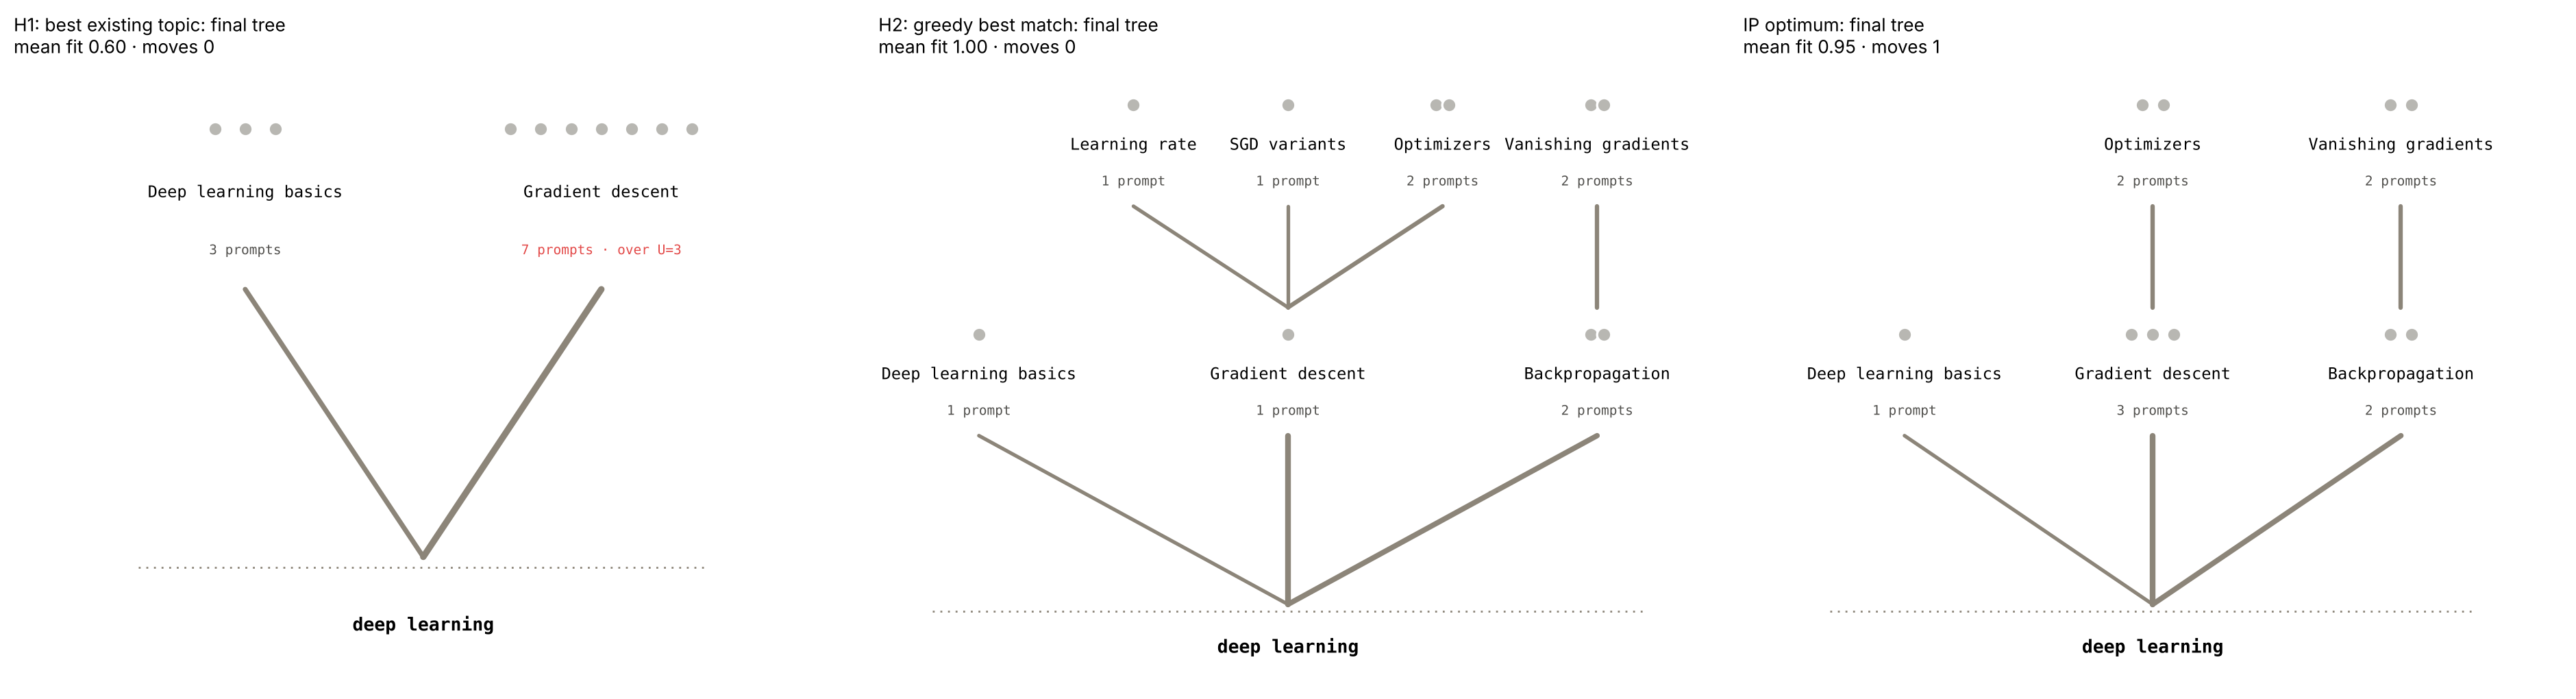

In [19]:
show_final_trees(HISTORIES, metrics=lambda h: f"mean fit {session_metrics(h)['mean fit']:.2f} · moves {session_metrics(h)['moves']}")

**Discussion (to be written for the report).** H1 never creates topics, so prompts about backpropagation and optimizers pile up in *Gradient descent*, which ends far over $U$ with the lowest fit. H2 creates a topic for every proposal: its fit is perfect, but it leaves *Learning rate* and *SGD variants* with a single prompt each, i.e. a longer tree that groups nothing. The IP sits in between: it accepts a slightly lower fit for two prompts, keeps the tree small and balanced, and needs a single move (step 7) to fix an earlier decision once more evidence arrived. Which balance is right for learners is exactly what the what-if analysis below and the Milestone 4 study examine.

To look at the alternatives step by step, run `show_session(HISTORIES["H1: best existing topic"])` or `show_session(HISTORIES["H2: greedy best match"])`.

# 8. What-if analysis
***
We re-run the **whole session** for different weights. Each row shows the sequence of actions over the eight steps (a = add, b = new branch, c = new tree, e = reorganize), so one can see directly where the behaviour changes.

**How much do we value stability?** $F$ is the fixed cost of moving anything. $F = 0$ allows reorganizing freely; large $F$ freezes old prompts.

In [20]:
def sweep(name, values):
    rows = []
    for v in values:
        hist = run_session(params={**PARAMS, name: v})
        m = session_metrics(hist)
        rows.append({name: v, "actions (steps 1-8)": " ".join(code_of(h["action"]) for h in hist),
                     "topics": m["topics"], "moves": m["moves"], "mean fit": m["mean fit"],
                     "topics over U": m["topics over U"]})
    return pd.DataFrame(rows).set_index(name)

sweep("F", [0.0, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40])

,actions (steps 1-8),topics,moves,mean fit,topics over U
F,,,,,
0.00,a c a a e a e a,5,2,0.950,0
0.05,a c a a b a e a,5,1,0.950,0
0.10,a c a a b a e a,5,1,0.950,0
0.15,a c a a b a e a,5,1,0.950,0
0.20,a c a a b a e a,5,1,0.950,0
0.25,a c a a b a e a,5,1,0.950,0
0.30,a c a a b a e a,5,1,0.950,0
0.40,a c a a b a b a,5,0,0.925,0


**How expensive is a new topic?** $\lambda$ controls how readily the tree grows.

In [21]:
sweep("lam", [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.7])

,actions (steps 1-8),topics,moves,mean fit,topics over U
lam,,,,,
0.0,b c a b b b a a,7,0,1.000,0
0.1,b c a b b b a a,7,0,1.000,0
0.2,a c a a b a e a,5,1,0.950,0
0.3,a c a a b a e a,5,1,0.950,0
0.4,a a a a e e a a,4,2,0.825,0
0.5,a a a a e e a a,4,2,0.825,0
0.7,a a a a a e a a,3,2,0.750,2


**How large may a topic get?** $U$ decides when a topic counts as overloaded.

In [22]:
sweep("U", [2, 3, 4, 5, 6])

,actions (steps 1-8),topics,moves,mean fit,topics over U
U,,,,,
2,a c a b b b a a,6,0,0.975,0
3,a c a a b a e a,5,1,0.950,0
4,a c a a b a e a,5,1,0.950,0
5,a c a a b a e a,5,1,0.950,0
6,a c a a b a e a,5,1,0.950,0


# 9. Notes for the critical examination
***
- **Scores.** All fit values come from an LLM judge (model, date and prompt in `judge_scores.json` and the appendix). Its consistency across runs and its agreement with two human raters are reported in Section 2; the decisions with a small margin (Section 6) are the ones most sensitive to judge errors.
- **Assumptions.** $U$, $L$ and $w_p$ are educated guesses ($w_p = 1$ for all prompts); with real users they could be estimated from how often people reopen past prompts and how long they search for them.
- **Myopic.** Each step is optimal on its own, but the sequence is not optimized as a whole: the IP does not know which prompts will come next.
- **Simplifications.** Candidate topics have a fixed parent, one subject only, at most one new topic per step, old topics are never removed.
- **Milestone 4.** Run the model after every prompt of the scripted study session and implement the resulting sequence of trees as condition B; condition A uses rule H2 (or the chronological list).

# Appendix: the judge prompt
***
The exact text sent to the judge (`judge.py`, also stored in `judge_scores.json`), for the report's appendix. Below it, one example request.

In [23]:
import judge
print("=== system prompt ===\n" + judge.SYSTEM_PROMPT)
print("\n=== example request (topic order and ids are shuffled in every call) ===")
print(judge.build_request(all_prompts()["n6"], all_topics(), __import__("random").Random(0))[0])

=== system prompt ===
You grade how well a student's question fits topics of a knowledge tree.

A study tool sorts every question a student asks an AI tutor into a tree of topics. For one question
you get a list of topics, each with its path in the tree. Rate EACH topic independently with this rubric:

5 = the question is squarely about this topic; this is where a student would look for it.
4 = the question belongs to a more specific subtopic of this topic, and that subtopic is NOT in the list.
3 = same broader area (same subject or a neighbouring topic), but a different topic.
2 = loosely related: shares some terms or background knowledge.
1 = unrelated.

Rules:
- Rate every topic in the list exactly once. Several topics may get the same score.
- Judge the meaning of the question, not shared words.
- If a more specific topic in the list fits exactly, give it 5; its parent then usually gets 3 or 4,
  never 5 for the same reason.
- Answer with JSON only, no other text, in exactly this f